In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_excel(r"C:\Users\ROSHAN\Desktop\EDA\bear_null2.xlsx")
df
# "C:\Users\ROSHAN\OneDrive\Desktop\EDA\bear_null2.xlsx"

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
188,Venezuela,76,100,3,7.7,South America
189,Vietnam,111,2,1,2.0,Asia
190,Yemen,6,0,0,0.1,Asia
191,Zambia,32,19,4,2.5,Africa


In [5]:
df.isnull().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

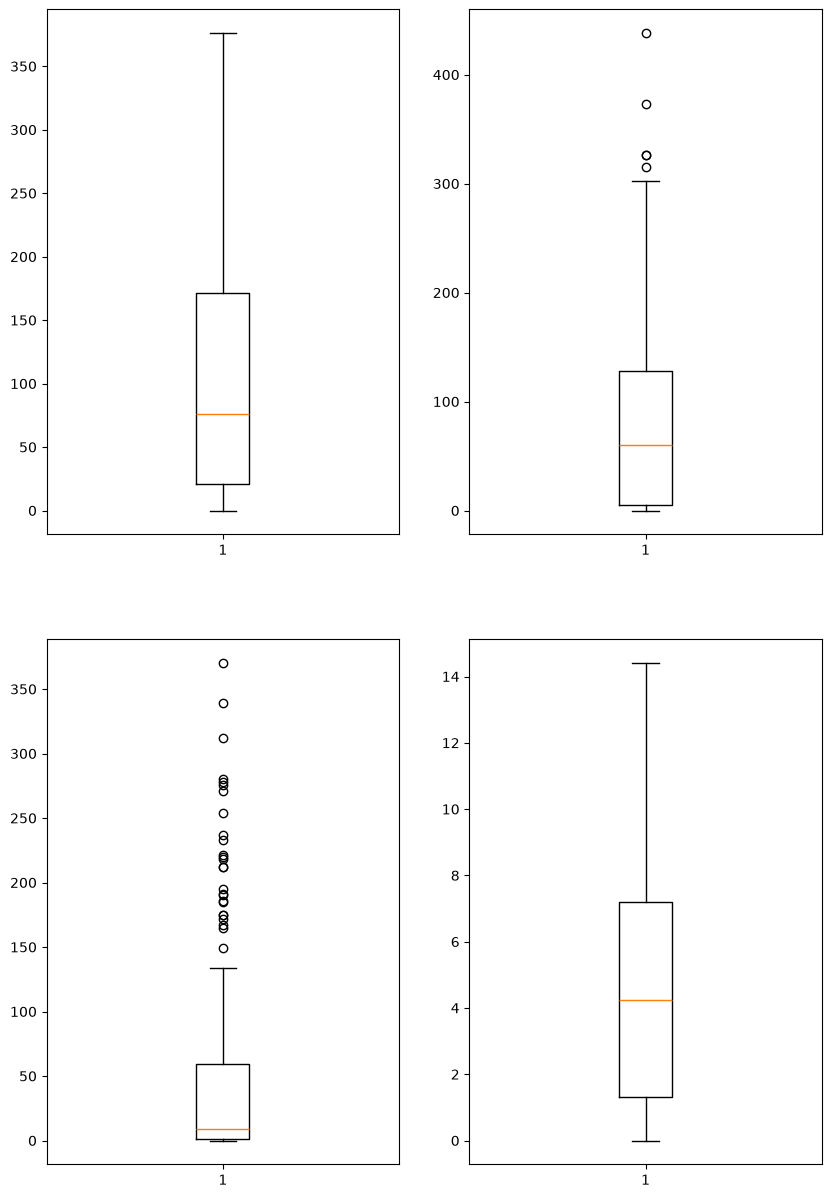

In [6]:
plt.figure(figsize=(10,15))
plt.subplot(2,2,1)
plt.boxplot(df['beer_servings'])
plt.subplot(2,2,2)
plt.boxplot(df['spirit_servings'])
plt.subplot(2,2,3)
plt.boxplot(df['wine_servings'])
plt.subplot(2,2,4)
plt.boxplot(df['total_litres_of_pure_alcohol'])
plt.show()

In [7]:
Q1 = np.percentile(df['spirit_servings'],25,method='midpoint')
Q2 = np.percentile(df['spirit_servings'],50,method='midpoint')
Q3 = np.percentile(df['spirit_servings'],75,method='midpoint')

print(Q1)
print(Q2)
print(Q3)

5.0
60.0
128.0


In [8]:
IQR = Q3 - Q1
print(IQR)

123.0


In [9]:
upper_limit = Q3+1.5*IQR
lower_limit = Q1-1.5*IQR
print(upper_limit)
print(lower_limit)

312.5
-179.5


In [10]:
outlier=[]
for x in df['spirit_servings']:
    if((x>upper_limit) or (x<lower_limit)):
        outlier.append(x)
outlier

[373, 438, 326, 326, 315]

In [11]:
df1 = (df['spirit_servings'] > upper_limit ) | (df['spirit_servings']<lower_limit)
df1

0      False
1      False
2      False
3      False
4      False
       ...  
188    False
189    False
190    False
191    False
192    False
Name: spirit_servings, Length: 193, dtype: bool

In [12]:
x = df.loc[df1]
x

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
15,Belarus,142,373,42,14.4,Europe
68,Grenada,199,438,28,11.9,North America
73,Haiti,1,326,1,5.9,North America
141,Russian Federation,247,326,73,11.5,Asia
144,St. Lucia,171,315,71,10.1,North America


In [13]:
df.drop(x.index,inplace=True)

In [14]:
df.shape

(188, 6)

In [15]:
df = df.reset_index(drop=True)

In [16]:
df

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
183,Venezuela,76,100,3,7.7,South America
184,Vietnam,111,2,1,2.0,Asia
185,Yemen,6,0,0,0.1,Asia
186,Zambia,32,19,4,2.5,Africa


In [17]:
df.isnull().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

In [18]:
outlier=[]
for x in df['spirit_servings']:
    if((x>upper_limit) or (x<lower_limit)):
        outlier.append(x)
outlier

[]

In [19]:
df.to_excel(r"C:\Users\ROSHAN\Desktop\EDA\nov_12.xlsx")

In [21]:
df.to_excel(r"C:\Users\ROSHAN\Desktop\EDA\EDA_nov_12.xlsx",index=False)